# NN_L10_battery_learning

**Learning curves of tabular Q-learning and a double deep Q-network for battery dispatch: revenue per day on the 2024 validation year after each training epoch.**

Neural Networks and Deep Learning (NN), Lecture 10 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L10/NN_L10_battery_learning/NN_L10_battery_learning.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

yesterday's plan, 2024 (EUR per day) = 289.0   [bat.naive_valid_day]


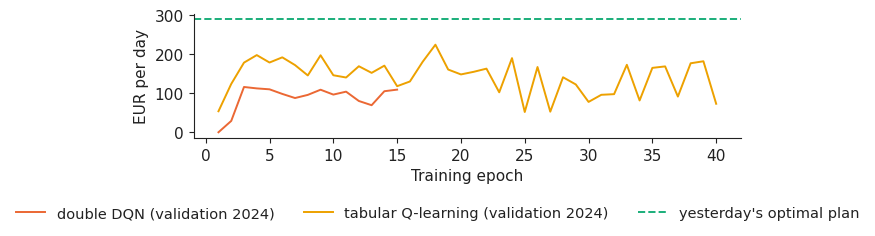

In [3]:
import torch, torch.nn as nn
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
END = '2026-10-31'                                   # last complete month of the course data
x = x.loc[:END + ' 23:59']
x['day'] = x.index.tz_localize(None).normalize(); x['hour'] = x.index.hour
def day_matrix(zone):
    d = x[['day', 'hour', zone]].dropna(); n = d.groupby('day')[zone].count()
    return d[d.day.isin(n[n == 24].index)].pivot_table(index='day', columns='hour', values=zone).sort_index()
RO = day_matrix('RO')
E_MAX, ETA = 2, 0.85
ETA_C = ETA_D = np.sqrt(ETA); ACTS = np.array([-1, 0, 1])
def reward(p, a): return np.where(a > 0, ETA_D * p, np.where(a < 0, -p / ETA_C, 0.0))
def dp_days(P):
    D = P.shape[0]; V = np.zeros((D, 25, E_MAX + 1)); A = np.zeros((D, 24, E_MAX + 1), dtype=int)
    for h in range(23, -1, -1):
        best = np.full((D, E_MAX + 1), -np.inf); arg = np.zeros((D, E_MAX + 1), dtype=int)
        for s in range(E_MAX + 1):
            for a in ACTS:
                if 0 <= s - a <= E_MAX:
                    q = reward(P[:, h], a) + V[:, h + 1, s - a]; b = q > best[:, s]; best[b, s] = q[b]; arg[b, s] = a
        V[:, h] = best; A[:, h] = arg
    return V, A
P = RO.values; days = RO.index
ok = np.array([i >= 7 and (days[i] - days[i-1]).days == 1 and (days[i] - days[i-7]).days == 7 for i in range(len(days))])
iTR = np.where(ok & (days.year >= 2019) & (days.year <= 2023))[0]; iVA = np.where(ok & (days.year == 2024))[0]
iTE = np.where(ok & (days.year >= 2025))[0]
V, A = dp_days(P)
plan = np.zeros((len(P), 24), int); s = np.zeros(len(P), int)
for h in range(24):
    a = A[np.arange(len(P)), h, s]; plan[:, h] = a; s = s - a
def run_plan(Pd, acts):
    s = np.zeros(len(Pd), int); tot = np.zeros(len(Pd))
    for h in range(24):
        a = acts[:, h].copy(); a[(a > 0) & (s == 0)] = 0; a[(a < 0) & (s == E_MAX)] = 0; tot += reward(Pd[:, h], a); s = s - a
    return tot
naive = np.full(len(P), np.nan); naive[1:] = run_plan(P[1:], plan[:-1])
QB = P.argsort(1).argsort(1) // 6
def mask_of(s):
    m = np.ones((len(s), 3), bool); m[:, 0] = s < E_MAX; m[:, 2] = s > 0; return m
def greedy_q(Q, idx):
    s = np.zeros(len(idx), int); tot = np.zeros(len(idx)); B = QB[idx - 1]
    for h in range(24):
        q = Q[h, B[:, h], s].copy(); q[~mask_of(s)] = -np.inf; a = ACTS[q.argmax(1)]; tot += reward(P[idx, h], a); s = s - a
    return tot
def q_learning(seed, epochs=40):
    rng = np.random.default_rng(seed); Q = np.zeros((24, 4, E_MAX + 1, 3)); best = (-np.inf, None); hist = []
    for ep in range(epochs):
        eps = max(0.05, 1.0 - ep / (0.6 * epochs))
        for d in rng.permutation(iTR):
            s, b = 0, QB[d - 1]
            for h in range(24):
                feas = [k for k, a in enumerate(ACTS) if 0 <= s - a <= E_MAX]
                k = feas[rng.integers(len(feas))] if rng.random() < eps else feas[int(np.argmax(Q[h, b[h], s, feas]))]
                r_ = float(reward(P[d, h], ACTS[k])) / 100.0; s2 = s - ACTS[k]
                tgt = r_ if h == 23 else r_ + Q[h + 1, b[h + 1], s2, [j for j, a2 in enumerate(ACTS) if 0 <= s2 - a2 <= E_MAX]].max()
                Q[h, b[h], s, k] += 0.05 * (tgt - Q[h, b[h], s, k]); s = s2
        va = greedy_q(Q, iVA).mean(); hist.append(va)
        if va > best[0]: best = (va, Q.copy())
    return best[1], hist
def zz(v): return (v - v.mean()) / (v.std() + 1.0)
FEAT = {d: np.concatenate([zz(P[d-1]), zz(P[d-7]), np.eye(7)[days[d].dayofweek]]) for d in np.concatenate([iTR, iVA, iTE])}
def obs(dl, h, s):
    return np.concatenate([np.stack([FEAT[d] for d in dl]), np.tile(np.eye(24)[h], (len(dl), 1)), np.eye(E_MAX + 1)[s]], 1).astype(np.float32)
d_in = obs(iTR[:1], 0, np.zeros(1, int)).shape[1]
def mk(): return nn.Sequential(nn.Linear(d_in, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 3))
def greedy_dqn(net, idx):
    s = np.zeros(len(idx), int); tot = np.zeros(len(idx))
    with torch.no_grad():
        for h in range(24):
            q = net(torch.from_numpy(obs(idx, h, s))).numpy(); q[~mask_of(s)] = -1e9; a = ACTS[q.argmax(1)]
            tot += reward(P[idx, h], a); s = s - a
    return tot
def dqn(seed, epochs=15, updates=20):
    torch.manual_seed(seed); rng = np.random.default_rng(seed); net, tgt = mk(), mk(); tgt.load_state_dict(net.state_dict())
    opt = torch.optim.Adam(net.parameters(), lr=3e-4); buf = []; best = (-np.inf, None); hist = []
    for ep in range(epochs):
        eps = max(0.05, 1 - ep / (0.6 * epochs)); s = np.zeros(len(iTR), int)
        for h in range(24):
            o = obs(iTR, h, s); m = mask_of(s)
            with torch.no_grad(): q = net(torch.from_numpy(o)).numpy()
            q[~m] = -1e9; k = q.argmax(1); rnd = rng.random(len(iTR)) < eps; k[rnd] = (rng.random((rnd.sum(), 3)) * m[rnd]).argmax(1)
            a = ACTS[k]; s2 = s - a
            buf.append((o, k, reward(P[iTR, h], a) / 100, obs(iTR, min(h + 1, 23), s2), mask_of(s2), np.full(len(iTR), h == 23)))
            buf = buf[-96:]; s = s2; O, K, R, O2, M2, DN = (np.concatenate(z) for z in zip(*buf))
            for _ in range(updates):
                j = rng.integers(0, len(O), 512)
                with torch.no_grad():
                    q2 = net(torch.from_numpy(O2[j])); q2[torch.from_numpy(~M2[j])] = -1e9
                    y = torch.from_numpy(R[j].astype(np.float32)) + tgt(torch.from_numpy(O2[j])).gather(1, q2.argmax(1, keepdim=True)).squeeze(1) * torch.from_numpy(~DN[j]).float()
                loss = nn.functional.smooth_l1_loss(net(torch.from_numpy(O[j])).gather(1, torch.from_numpy(K[j]).long()[:, None]).squeeze(1), y)
                opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 5.0); opt.step()
                with torch.no_grad():
                    for pt, pn in zip(tgt.parameters(), net.parameters()): pt.mul_(0.995).add_(0.005 * pn)
        va = greedy_dqn(net, iVA).mean(); hist.append(va)
        if va > best[0]: best = (va, {k_: v.clone() for k_, v in net.state_dict().items()})
    net.load_state_dict(best[1]); return net, hist
_, hq = q_learning(20261108)
_, hd = dqn(20261108)
show('bat.naive_valid_day', "yesterday's plan, 2024 (EUR per day)", round(float(naive[iVA].mean()), 0))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
ax.plot(range(1, len(hd) + 1), hd, color=PAL['model'], label='double DQN (validation 2024)')
ax.plot(range(1, len(hq) + 1), hq, color=PAL['alt'], label='tabular Q-learning (validation 2024)')
ax.axhline(naive[iVA].mean(), color=PAL['benchmark'], ls='--', label="yesterday's optimal plan")
ax.set_xlabel('Training epoch'); ax.set_ylabel('EUR per day'); legend_bottom(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig('battery_learning.png', dpi=200, transparent=True, bbox_inches='tight'); plt.show()